# Challenge 4: Quantum Correlation Switch

**IBM Quantum | Vishnu Institute of Technology | Qiskit Fall Fest 2026**

For this challenge, students must have a working Python environment with the following packages installed:
- `qiskit` v2.1.0 or newer
- `qiskit-ibm-runtime` v0.40.1 or newer
- `qiskit.visualization`
- `numpy`
- `pylatexenc`

To set up and install the packages above, see the [Install Qiskit](https://quantum.cloud.ibm.com/docs/guides/install-qiskit) guide. In order to run jobs on real quantum computers, you need an IBM Quantum&reg; account (see [Set up your IBM Cloud&reg; account](https://quantum.cloud.ibm.com/docs/guides/cloud-setup)) with an **API key** and an **instance (CRN)**.

In [1]:
# Uncomment and modify this line as needed to install dependencies
#%pip install --upgrade "qiskit[visualization]" qiskit-ibm-runtime numpy pylatexenc

In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram

## Introduction

In Challenge 3 we saw how a quantum circuit can produce correlated outcomes. Now we design a circuit that **switches** between correlated and opposite measurement outcomes using only a few gates.

- **Part A:** correlated outcomes, predominantly `00` and `11`
- **Part B:** opposite outcomes, predominantly `01` and `10`
- **Part C:** compare both with histograms

### Gates used

**Hadamard ($H$)** creates superposition, **CNOT** creates entanglement, and the **$X$ gate** flips a qubit.

## Qiskit patterns framework

We follow the Qiskit patterns workflow, a general procedure for solving problems with a quantum computer:

1. **Mapping** the problem to quantum circuits
2. **Optimizing** the circuits for the target hardware
3. **Executing** on the hardware
4. **Post-processing** the results

All circuits below use `measure_all()`, so the results are stored in the classical register called `meas`. Remember that Qiskit uses **little-endian** notation: in a bitstring such as `01`, the rightmost bit is qubit 0.

#### 1. Mapping

**Part A:** $H$ on qubit 0, then $CNOT(q_0, q_1)$, giving $\frac{1}{\sqrt{2}}(\vert 00\rangle + \vert 11\rangle)$.

**Part B:** the same circuit plus an $X$ gate on qubit 1, giving $\frac{1}{\sqrt{2}}(\vert 01\rangle + \vert 10\rangle)$.

Both circuits use exactly 2 qubits and at most 3 gates before measurement.

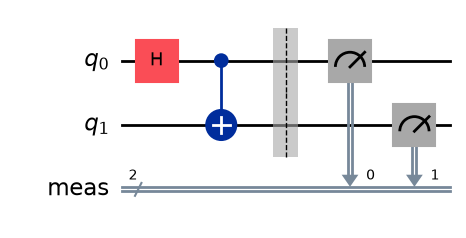

In [3]:
# Part A: correlated outcomes
qc_a = QuantumCircuit(2)
qc_a.h(0)
qc_a.cx(0, 1)
qc_a.measure_all()
qc_a.draw("mpl")

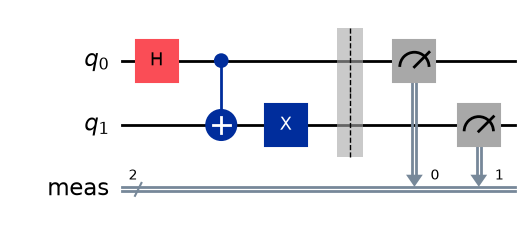

In [4]:
# Part B: opposite outcomes (add an X gate on qubit 1)
qc_b = QuantumCircuit(2)
qc_b.h(0)
qc_b.cx(0, 1)
qc_b.x(1)
qc_b.measure_all()
qc_b.draw("mpl")

### Think before you run: predictions

- **Part A:** `00` and `11` should dominate (about 50 each).
- **Part B:** `01` and `10` should dominate (about 50 each).
- **Will all four outcomes appear?** Ideally no: each circuit allows only two of the four bitstrings, because the entangled state only contains two basis states. On real hardware, noise may add a few stray counts in the other two.
- **Why are some outcomes much more frequent?** Their amplitudes are non-zero ($1/\sqrt{2}$), while the amplitudes of the other two outcomes are zero.

#### 2. Optimizing

Next, we optimize the circuits for the quantum hardware using the transpiler. It assigns the logical qubits to physical qubits on the processor and rewrites the gates in terms of the hardware's native gate set. We choose an optimization level from 0 (none) to 3 (highest); see [Set transpiler optimization level](https://quantum.cloud.ibm.com/docs/guides/set-optimization). The transpiled circuit looks different from the logical one we mapped.

In [5]:
# Load the Qiskit Runtime service
from qiskit_ibm_runtime import QiskitRuntimeService

# Syntax for first saving your credentials. Delete these lines after saving them once,
# and never share a notebook that contains your real API key.
QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    instance="<YOUR_INSTANCE_CRN>",
    token="<YOUR_API_KEY>",
    overwrite=True,
    set_as_default=True,
)
service = QiskitRuntimeService(channel="ibm_quantum_platform")

# Load saved credentials (use this line on later runs)
# service = QiskitRuntimeService()

# Use the least busy backend, or uncomment the loading of a specific backend.
backend = service.least_busy(operational=True, simulator=False)
# backend = service.backend("ibm_brisbane")
print(backend.name)

ibm_marrakesh


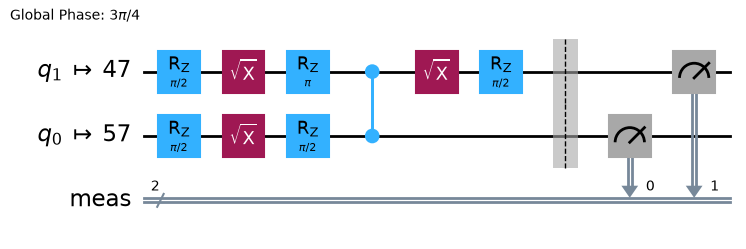

In [6]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

circuits = [qc_a, qc_b]
isa_circuits = pm.run(circuits)

isa_circuits[0].draw("mpl", idle_wires=False)

#### 3. Executing

A "Sampler" is a primitive that samples the possible states resulting from a quantum circuit and collects statistics on what is measured and with what probability. We send **all circuits as a single job** with **100 shots** each.

In [7]:
# Load the Runtime primitive
from qiskit_ibm_runtime.executor_sampler import Sampler

sampler = Sampler(mode=backend)

In [8]:
job = sampler.run(isa_circuits, shots=100)
print("Job ID:", job.job_id())

res = job.result()   # waits until the job finishes
all_counts = [r.data.meas.get_counts() for r in res]
counts_a, counts_b = all_counts
print("Part A:", counts_a)
print("Part B:", counts_b)

Job ID: db5qqa2mb58s738asq10
Part A: {'00': 48, '11': 48, '01': 2, '10': 2}
Part B: {'10': 54, '01': 46}


#### 4. Post-processing

Now we view the results as histograms of the 100 shots of each circuit.

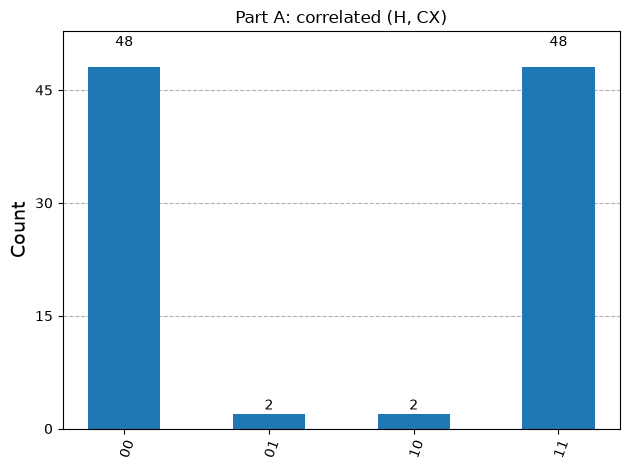

In [9]:
plot_histogram(counts_a, title="Part A: correlated (H, CX)")

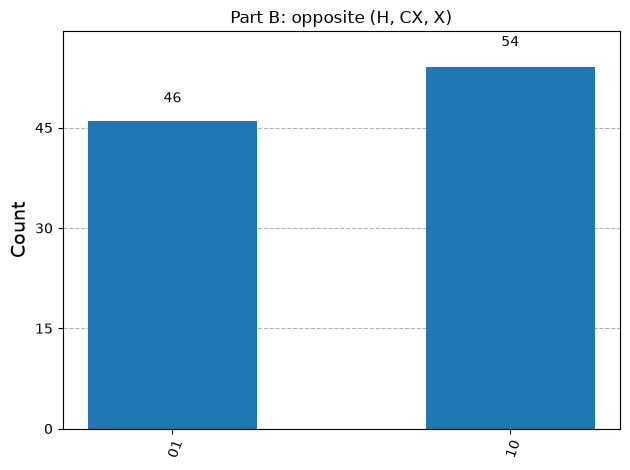

In [10]:
plot_histogram(counts_b, title="Part B: opposite (H, CX, X)")

#### Part C: Compare

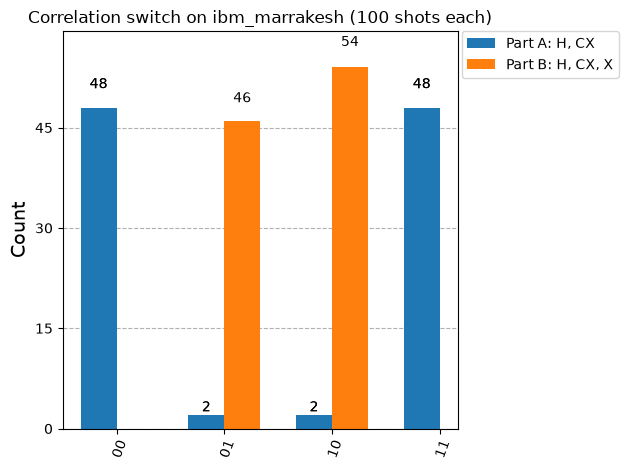

In [11]:
plot_histogram([counts_a, counts_b],
               legend=["Part A: H, CX", "Part B: H, CX, X"],
               title=f"Correlation switch on {backend.name} (100 shots each)")

In [12]:
outcomes = ["00", "01", "10", "11"]
print(f"{'Outcome':10s}{'Part A (correlated)':>22s}{'Part B (opposite)':>20s}")
for o in outcomes:
    print(f"{o:10s}{counts_a.get(o, 0):>22d}{counts_b.get(o, 0):>20d}")

Outcome      Part A (correlated)   Part B (opposite)
00                            48                   0
01                             2                  46
10                             2                  54
11                            48                   0


### Explanation

- **Dominant outcomes in Part A:** `00` and `11`. The two qubits always agree.
- **Dominant outcomes in Part B:** `01` and `10`. The two qubits always disagree.
- **What changed between the circuits:** one extra $X$ gate on qubit 1, applied after the CNOT and before measurement.
- **Why the relationship changed:** $H$ and CNOT entangle the qubits into $\frac{1}{\sqrt{2}}(\vert 00\rangle + \vert 11\rangle)$, so measuring one qubit fixes the other to the same value. The $X$ gate flips qubit 1 in every branch ($\vert 00\rangle\rightarrow\vert 01\rangle$, $\vert 11\rangle\rightarrow\vert 10\rangle$). The entanglement is preserved, but the relationship becomes "always opposite". The $X$ gate acts as a switch between correlation and anti-correlation.

An ideal quantum computer would only give the predicted outcomes, but real hardware has noise (gate and readout errors), so a few stray counts are expected.

## Conclusion

### Critical concepts:

- **Entanglement** ($H$ followed by CNOT) creates strong correlations between measurement outcomes.
- Only the allowed **basis states** of the entangled state show up when measured; the other outcomes have zero amplitude.
- A single **$X$ gate** changes which bitstrings are allowed, switching **correlation** to **anti-correlation**.
- Real hardware **noise** adds a few unexpected counts to the ideal result.